# Week 2 – Advanced Data Visualization and Storytelling
**Dataset:** cleaned Telco Customer Churn data from Week 1 (`data/processed/telco_churn_clean.csv`)
**Author:** Anish Goyal

In Week 1 I found *which* features are linked to churn. This week the goal is different: turn those findings
into a story that a non-technical manager can follow. The story has four parts:

1. **When** do customers leave?
2. **Who** is leaving?
3. **What does it cost** the company?
4. **What can be done** about it?

Every chart below has a title that states the takeaway, so the reader gets the message even without reading the axis labels.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.express as px
from pathlib import Path

df = pd.read_csv("../data/processed/telco_churn_clean.csv")

FIG = Path("../reports/figures/week2")
HTML = Path("../reports/interactive")
FIG.mkdir(parents=True, exist_ok=True)
HTML.mkdir(parents=True, exist_ok=True)

# one accent colour for "churn / risk", muted colours for everything else
ORANGE, BLUE, GREY, DARK = "#E8743B", "#4C78A8", "#B0B0B0", "#333333"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
})

def subtitle(ax, text):
    ax.text(0, 1.02, text, transform=ax.transAxes, fontsize=10, color="#555555", va="bottom")

print(df.shape)
print(f"Overall churn rate: {df['ChurnFlag'].mean():.1%}")

(7043, 23)
Overall churn rate: 26.5%


## Visualization 1 – When do customers leave? (retention curves)
A bar chart of churn by tenure only shows a snapshot. A **retention curve** shows the journey: out of 100 customers who
join, how many are still here after *n* months? I estimated it with the Kaplan–Meier method, which correctly treats
customers who haven't left yet as "still active" instead of ignoring them. I wrote the estimator in plain pandas so every step is visible.

In [2]:
def retention_curve(data, max_month=72):
    survival, s = [], 1.0
    for t in range(max_month + 1):
        at_risk = (data["tenure"] >= t).sum()
        churned = ((data["tenure"] == t) & (data["ChurnFlag"] == 1)).sum()
        if at_risk > 0:
            s *= 1 - churned / at_risk
        survival.append(s)
    return pd.Series(survival, index=range(max_month + 1))

curves = {c: retention_curve(g) for c, g in df.groupby("Contract")}
pd.DataFrame({c: s.loc[[1, 6, 12, 24, 48, 72]] for c, s in curves.items()}).mul(100).round(1)

,Month-to-month,One year,Two year
1,90.2,100.0,100.0
6,78.6,99.7,100.0
12,70.3,99.1,100.0
24,58.6,97.8,100.0
48,39.7,91.7,99.6
72,12.9,56.8,93.6


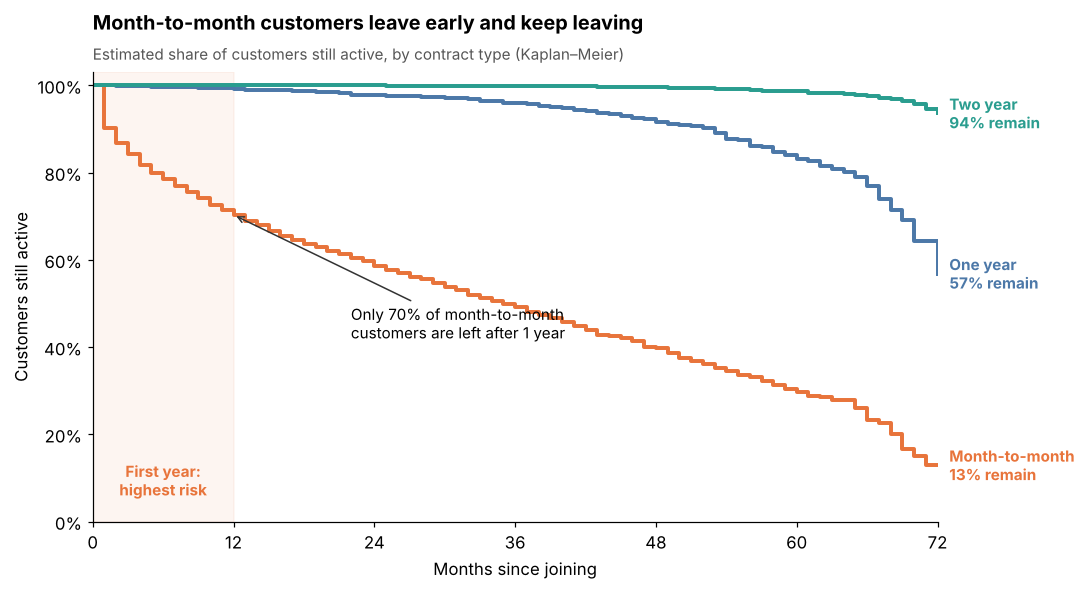

In [3]:
colors = {"Month-to-month": ORANGE, "One year": BLUE, "Two year": "#2A9D8F"}
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.axvspan(0, 12, color=ORANGE, alpha=0.07)
ax.text(6, 0.06, "First year:\nhighest risk", ha="center", color=ORANGE, fontsize=10, fontweight="bold")

for name, s in curves.items():
    ax.step(s.index, s.values, where="post", lw=2.6, color=colors[name])
    ax.text(73, s.iloc[-1], f"{name}\n{s.iloc[-1]:.0%} remain", va="center", color=colors[name], fontsize=10, fontweight="bold")

m12 = curves["Month-to-month"].loc[12]
ax.annotate(f"Only {m12:.0%} of month-to-month\ncustomers are left after 1 year",
            xy=(12, m12), xytext=(22, 0.42), fontsize=10,
            arrowprops=dict(arrowstyle="->", color=DARK))

ax.set_xlim(0, 72); ax.set_ylim(0, 1.03)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xticks(range(0, 73, 12))
ax.set_xlabel("Months since joining"); ax.set_ylabel("Customers still active")
ax.set_title("Month-to-month customers leave early and keep leaving", pad=28)
subtitle(ax, "Estimated share of customers still active, by contract type (Kaplan–Meier)")
plt.tight_layout()
plt.savefig(FIG / "v1_retention_curves.png", bbox_inches="tight")
plt.show()

**Why this chart:** a line that falls over time is the most natural way to show "losing customers", and step lines are
the standard for retention data. Labels sit at the end of each line instead of a legend so the reader does not have to look back and forth.

**What it says:** about 30% of month-to-month customers are gone within 12 months, and only ~13% would still be active after 6 years.
Two-year customers barely move (94% remain). The first year is where the battle is won or lost.

## Visualization 2 – Who is leaving? (contract × tenure heatmap)
Week 1 looked at contract and tenure separately. A heatmap lets us see both at once and check whether long tenure
"fixes" the month-to-month problem.

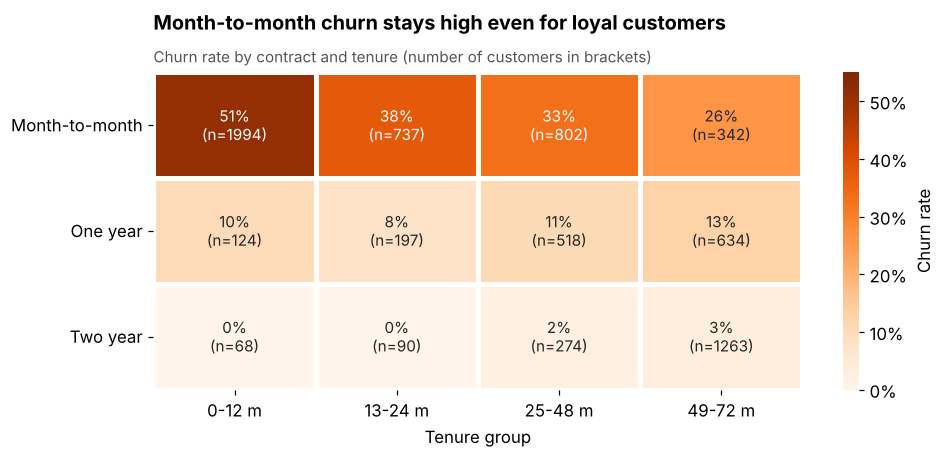

TenureGroup,0-12 m,13-24 m,25-48 m,49-72 m
Contract,,,,
Month-to-month,0.514,0.377,0.329,0.260
One year,0.105,0.081,0.106,0.129
Two year,0.000,0.000,0.022,0.033


In [4]:
rate = pd.crosstab(df["Contract"], df["TenureGroup"], values=df["ChurnFlag"], aggfunc="mean")
count = pd.crosstab(df["Contract"], df["TenureGroup"])
order = ["0-12 m", "13-24 m", "25-48 m", "49-72 m"]
rate, count = rate[order], count[order]

labels = rate.map(lambda v: f"{v:.0%}") + "\n(n=" + count.astype(str) + ")"

fig, ax = plt.subplots(figsize=(9, 4.3))
sns.heatmap(rate, annot=labels, fmt="", cmap="Oranges", vmin=0, vmax=0.55,
            linewidths=2, linecolor="white", cbar_kws={"format": mtick.PercentFormatter(1.0), "label": "Churn rate"},
            annot_kws={"fontsize": 10}, ax=ax)
ax.set_xlabel("Tenure group"); ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
ax.set_title("Month-to-month churn stays high even for loyal customers", pad=28)
subtitle(ax, "Churn rate by contract and tenure (number of customers in brackets)")
plt.tight_layout()
plt.savefig(FIG / "v2_contract_tenure_heatmap.png", bbox_inches="tight")
plt.show()
rate.round(3)

**Why this chart:** a heatmap is the clearest way to compare two categorical variables at once; the colour does the
work before the reader reads any number. Adding the customer count in each cell stops the reader from over-trusting small groups.

**What it says:** new month-to-month customers churn at 51%. Even after 4+ years, month-to-month churn is still 26%,
while two-year customers almost never leave (0–3%). Tenure helps, but the contract type matters more.

## Visualization 3 – What does it cost? (Pareto chart of lost revenue)
For a manager, "26% churn" is abstract. Money is not. I added up the monthly charges of every customer who left and
split that lost revenue by segment (contract + internet type).

In [5]:
lost = df[df["ChurnFlag"] == 1]
total_lost = lost["MonthlyCharges"].sum()
total_rev = df["MonthlyCharges"].sum()
print(f"Monthly revenue lost: ${total_lost:,.0f} out of ${total_rev:,.0f} ({total_lost/total_rev:.1%})")

short = {"Month-to-month": "M2M", "One year": "1-yr", "Two year": "2-yr", "Fiber optic": "Fiber", "No": "No internet", "DSL": "DSL"}
seg = (lost.groupby(["Contract", "InternetService"])["MonthlyCharges"].sum()
           .sort_values(ascending=False).reset_index())
seg["label"] = seg["Contract"].map(short) + "\n" + seg["InternetService"].map(short)
seg["cum_share"] = seg["MonthlyCharges"].cumsum() / total_lost
seg

Monthly revenue lost: $139,131 out of $456,117 (30.5%)


,Contract,InternetService,MonthlyCharges,label,cum_share
0,Month-to-month,Fiber optic,100482.00,M2M\nFiber,0.722212
1,Month-to-month,DSL,18367.25,M2M\nDSL,0.854226
2,One year,Fiber optic,10571.95,1-yr\nFiber,0.930212
3,One year,DSL,3356.25,1-yr\nDSL,0.954335
4,Two year,Fiber optic,3246.10,2-yr\nFiber,0.977666
5,Month-to-month,No,1997.85,M2M\nNo internet,0.992026
6,Two year,DSL,805.70,2-yr\nDSL,0.997817
7,One year,No,190.25,1-yr\nNo internet,0.999184
8,Two year,No,113.50,2-yr\nNo internet,1.000000


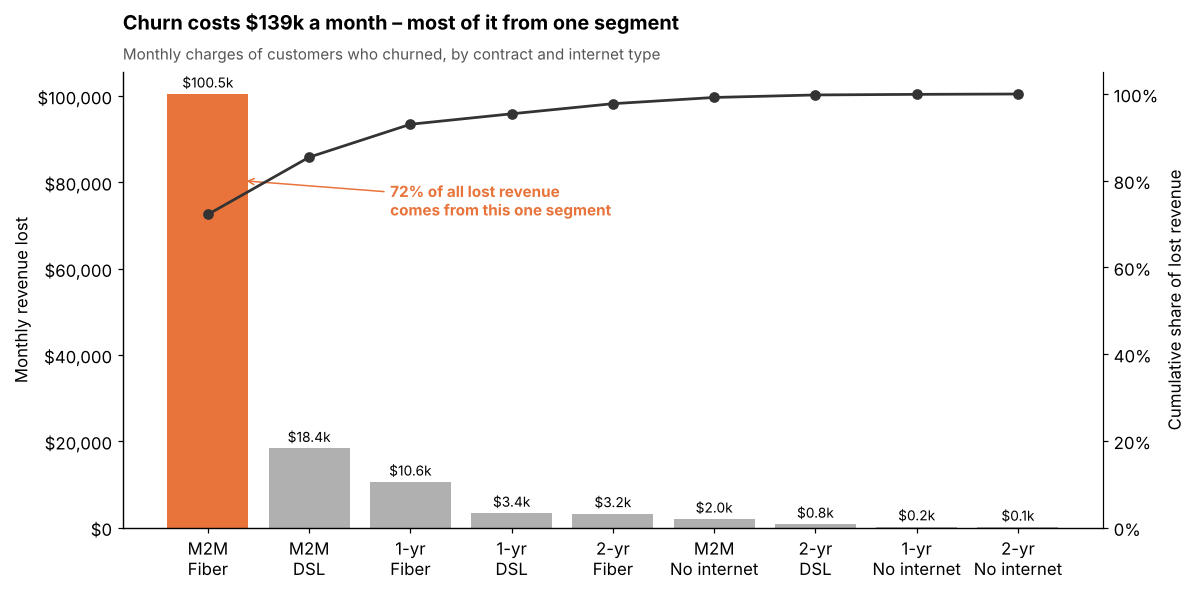

In [6]:
fig, ax = plt.subplots(figsize=(11, 5.5))
bar_colors = [ORANGE] + [GREY] * (len(seg) - 1)
bars = ax.bar(seg["label"], seg["MonthlyCharges"], color=bar_colors)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_ylabel("Monthly revenue lost")
for b, v in zip(bars, seg["MonthlyCharges"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 1500, f"${v/1000:,.1f}k", ha="center", fontsize=9)

ax2 = ax.twinx()
ax2.plot(seg["label"], seg["cum_share"], color=DARK, marker="o", lw=1.8)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.set_ylim(0, 1.05); ax2.set_ylabel("Cumulative share of lost revenue")
ax2.spines["right"].set_visible(True)

top = seg.iloc[0]
ax.annotate(f"{top['cum_share']:.0%} of all lost revenue\ncomes from this one segment",
            xy=(0.35, top["MonthlyCharges"] * 0.8), xytext=(1.8, top["MonthlyCharges"] * 0.72),
            fontsize=10, color=ORANGE, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=ORANGE))

ax.set_title(f"Churn costs ${total_lost/1000:,.0f}k a month – most of it from one segment", pad=28)
subtitle(ax, "Monthly charges of customers who churned, by contract and internet type")
plt.tight_layout()
plt.savefig(FIG / "v3_revenue_pareto.png", bbox_inches="tight")
plt.show()

**Why this chart:** a Pareto chart (sorted bars + cumulative line) answers "where should we focus?" in one look.
Only the most important bar is coloured; the rest are grey so they fade into the background.

**What it says:** churned customers were paying about **$139k per month**, which is **30.5%** of all monthly revenue
even though they are only 26.5% of customers. Month-to-month fiber customers alone account for **72%** of that loss.

## Visualization 4 – Why are they leaving? (add-on services dumbbell chart)
Customers with internet can buy six add-ons. Do any of them make customers stay? I compared churn for customers
*with* and *without* each add-on, **only among internet users** (otherwise customers with no internet would distort the "without" group).

In [7]:
addons = ["OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection", "StreamingTV", "StreamingMovies"]
net = df[df["InternetService"] != "No"]
dumb = pd.DataFrame({
    "without": [net.loc[net[a] == "No", "ChurnFlag"].mean() for a in addons],
    "with": [net.loc[net[a] == "Yes", "ChurnFlag"].mean() for a in addons],
}, index=addons)
dumb["gap_pp"] = (dumb["without"] - dumb["with"]) * 100
dumb = dumb.sort_values("gap_pp")
dumb.round(3)

,without,with,gap_pp
StreamingTV,0.335,0.301,3.453
StreamingMovies,0.337,0.299,3.739
DeviceProtection,0.391,0.225,16.626
OnlineBackup,0.399,0.215,18.397
TechSupport,0.416,0.152,26.469
OnlineSecurity,0.418,0.146,27.156


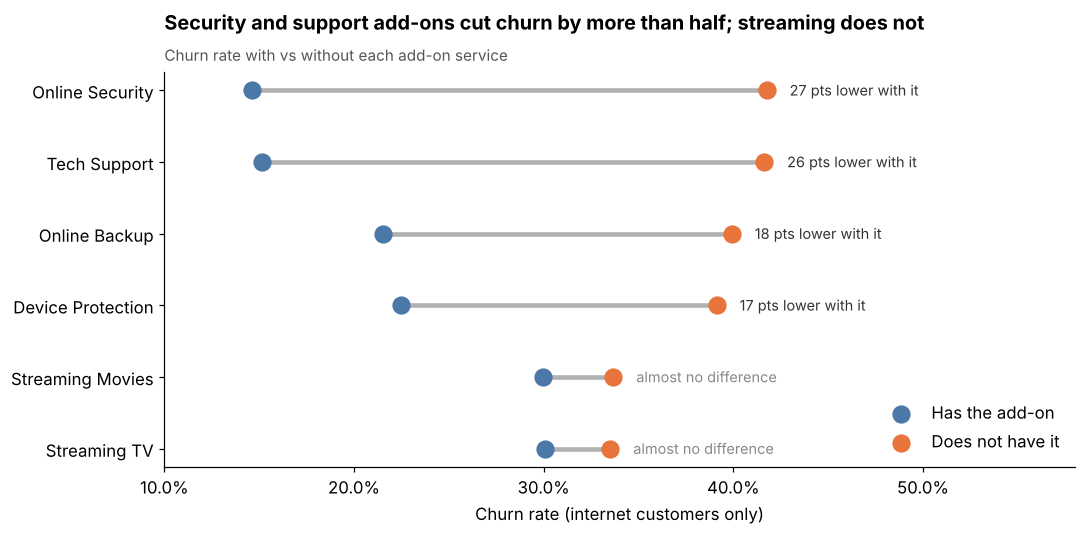

In [8]:
nice = {"OnlineSecurity": "Online Security", "TechSupport": "Tech Support", "OnlineBackup": "Online Backup",
        "DeviceProtection": "Device Protection", "StreamingTV": "Streaming TV", "StreamingMovies": "Streaming Movies"}
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(dumb))
ax.hlines(y, dumb["with"], dumb["without"], color=GREY, lw=3)
ax.scatter(dumb["with"], y, s=120, color=BLUE, zorder=3, label="Has the add-on")
ax.scatter(dumb["without"], y, s=120, color=ORANGE, zorder=3, label="Does not have it")
for i, (w, wo, g) in enumerate(zip(dumb["with"], dumb["without"], dumb["gap_pp"])):
    ax.text(wo + 0.012, i, f"{g:.0f} pts lower with it" if g > 5 else "almost no difference",
            va="center", fontsize=9.5, color=DARK if g > 5 else "#888888")
ax.set_yticks(y, [nice[a] for a in dumb.index])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0.1, 0.58)
ax.set_xlabel("Churn rate (internet customers only)")
ax.legend(loc="lower right", frameon=False)
ax.set_title("Security and support add-ons cut churn by more than half; streaming does not", pad=28)
subtitle(ax, "Churn rate with vs without each add-on service")
plt.tight_layout()
plt.savefig(FIG / "v4_addons_dumbbell.png", bbox_inches="tight")
plt.show()

**Why this chart:** a dumbbell chart shows two values and the gap between them for many categories, using less ink
than grouped bars. The length of the grey line *is* the effect size, so the reader can rank add-ons instantly.

**What it says:** customers without Online Security or Tech Support churn at ~42%, against ~15% for those who have them,
a gap of about 27 percentage points. Streaming add-ons make almost no difference (~3–4 points). Note that this shows
association, not proof that add-ons *cause* customers to stay.

## Visualization 5 – Putting it together: a simple risk score
The earlier charts each show one factor. In reality the factors stack up. I counted how many of five "red flags" each customer has:
1. month-to-month contract 2. fiber optic internet 3. pays by electronic check 4. joined in the last 12 months 5. has internet but no tech support.

In [9]:
flags = pd.DataFrame({
    "Month-to-month": df["Contract"] == "Month-to-month",
    "Fiber optic": df["InternetService"] == "Fiber optic",
    "Electronic check": df["PaymentMethod"] == "Electronic check",
    "Tenure <= 12 m": df["tenure"] <= 12,
    "No tech support": (df["TechSupport"] == "No") & (df["InternetService"] != "No"),
})
df["RiskFlags"] = flags.sum(axis=1)
ladder = df.groupby("RiskFlags").agg(customers=("ChurnFlag", "size"), churn_rate=("ChurnFlag", "mean"))
ladder

,customers,churn_rate
RiskFlags,,
0,1539,0.025341
1,1186,0.073356
2,1390,0.189928
3,1272,0.354560
4,1067,0.564199
5,589,0.723260


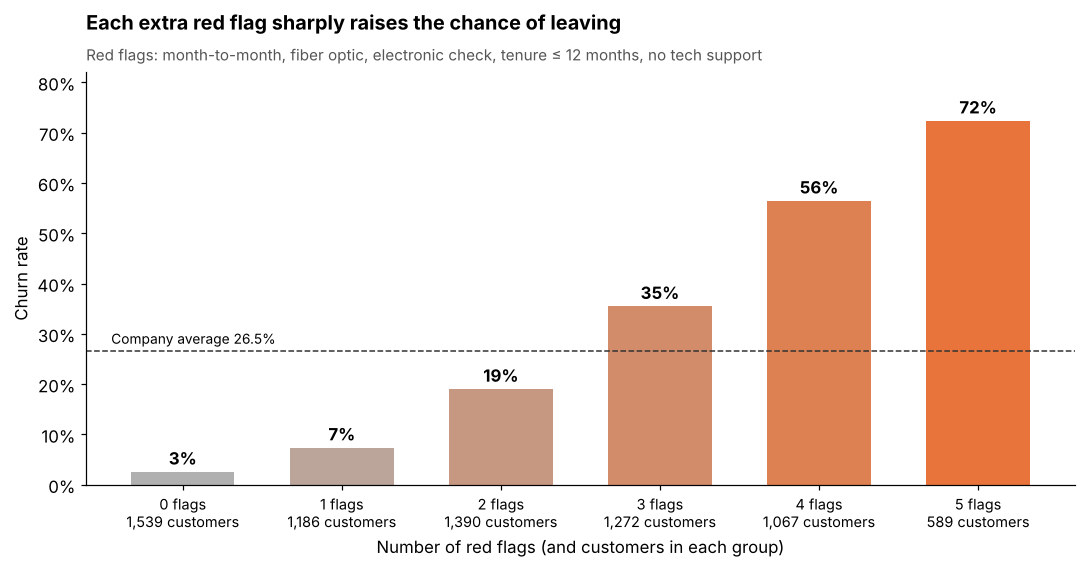

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.3))
shades = sns.blend_palette([GREY, ORANGE], n_colors=len(ladder))
bars = ax.bar(ladder.index.astype(str), ladder["churn_rate"], color=shades, width=0.65)
for b, (n, r) in zip(bars, ladder[["customers", "churn_rate"]].values):
    ax.text(b.get_x() + b.get_width() / 2, r + 0.015, f"{r:.0%}", ha="center", fontweight="bold")
ax.axhline(df["ChurnFlag"].mean(), ls="--", color=DARK, lw=1)
ax.text(-0.45, df["ChurnFlag"].mean() + 0.015, f"Company average {df['ChurnFlag'].mean():.1%}", fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 0.82)
ax.set_xticks(range(len(ladder)), [f"{i} flags\n{n:,} customers" for i, n in zip(ladder.index, ladder["customers"])], fontsize=9.5)
ax.set_xlabel("Number of red flags (and customers in each group)"); ax.set_ylabel("Churn rate")
ax.set_title("Each extra red flag sharply raises the chance of leaving", pad=28)
subtitle(ax, "Red flags: month-to-month, fiber optic, electronic check, tenure ≤ 12 months, no tech support")
plt.tight_layout()
plt.savefig(FIG / "v5_risk_ladder.png", bbox_inches="tight")
plt.show()

**Why this chart:** a simple bar "ladder" turns a multi-factor idea into one number that anyone can understand. The
colour gets warmer as risk rises, and customer counts inside the bars show each group is large enough to trust.

**What it says:** customers with no red flags churn at 2.5%. With all five, churn reaches **72%**, almost 30 times higher.
The 1,656 customers with 4 or 5 flags are the obvious list for a retention team to call first.

## Visualization 6 – The big picture (nested donut + interactive sunburst)
To close the story I wanted one overview chart: how the customer base is split by contract, and how much of each slice is lost.

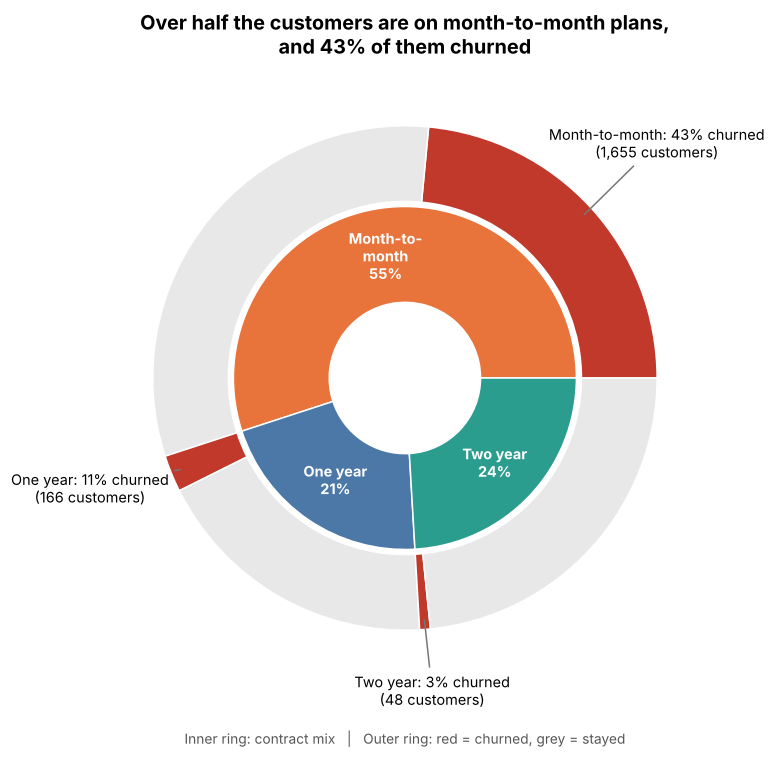

In [11]:
inner = df["Contract"].value_counts().reindex(["Month-to-month", "One year", "Two year"])
outer = df.groupby(["Contract", "Churn"], observed=True).size().reindex(
    pd.MultiIndex.from_product([inner.index, ["Yes", "No"]]))

fig, ax = plt.subplots(figsize=(8, 7))
ax.pie(inner, radius=0.68, colors=[ORANGE, BLUE, "#2A9D8F"],
       labels=[f"{c.replace('Month-to-month', 'Month-to-\nmonth')}\n{v/len(df):.0%}" for c, v in inner.items()],
       labeldistance=0.72, textprops=dict(color="white", fontsize=9.5, fontweight="bold", ha="center"),
       wedgeprops=dict(width=0.38, edgecolor="white"))
outer_colors = []
for c in inner.index:
    outer_colors += ["#C0392B", "#E8E8E8"]
wedges, _ = ax.pie(outer, radius=1.0, colors=outer_colors, wedgeprops=dict(width=0.3, edgecolor="white"))
for (c, ch), w, v in zip(outer.index, wedges, outer.values):
    if ch == "Yes":
        ang = np.deg2rad((w.theta1 + w.theta2) / 2)
        share = v / inner[c]
        ax.annotate(f"{c}: {share:.0%} churned\n({v:,} customers)", xy=(np.cos(ang) * 0.95, np.sin(ang) * 0.95),
                    xytext=(np.cos(ang) * 1.35, np.sin(ang) * 1.3), ha="center", fontsize=9.5,
                    arrowprops=dict(arrowstyle="-", color="#777777"))
ax.set_title("Over half the customers are on month-to-month plans,\nand 43% of them churned", loc="center")
ax.text(0, -1.45, "Inner ring: contract mix   |   Outer ring: red = churned, grey = stayed", ha="center", fontsize=9, color="#555555")
plt.tight_layout()
plt.savefig(FIG / "v6_contract_donut.png", bbox_inches="tight")
plt.show()

For readers who want to explore further, I also built an **interactive sunburst** with Plotly. Clicking a slice zooms
into it (e.g. Month-to-month → Fiber optic → Churned). It is saved as an HTML file that opens in any browser.

In [12]:
sun = df.groupby(["Contract", "InternetService", "Churn"], observed=True).size().reset_index(name="customers")
fig = px.sunburst(sun, path=["Contract", "InternetService", "Churn"], values="customers",
                  color="Churn", color_discrete_map={"Yes": "#C0392B", "No": "#9DB4D3", "(?)": "#DDDDDD"},
                  title="Customer base by contract → internet service → churn (click to zoom)")
fig.update_traces(textinfo="label+percent parent")
fig.update_layout(margin=dict(t=60, l=10, r=10, b=10))
fig.write_html(HTML / "churn_sunburst.html", include_plotlyjs="cdn")
fig.show()

## Summary of the data story
| Question | Answer from the visuals |
|---|---|
| When do customers leave? | Mostly in the first year; ~30% of month-to-month customers leave within 12 months |
| Who leaves? | Month-to-month customers, at every tenure level (26–51%) |
| What does it cost? | ~$139k per month (30.5% of revenue); 72% of it from month-to-month fiber customers |
| Why? | Missing security/support add-ons is strongly linked to churn; streaming is not |
| Who to target? | Customers with 4–5 red flags churn at 56–72% |

## Business implications
1. **Move customers to longer contracts.** Offer a discount or free month for switching from month-to-month to a 1-year plan, especially during the first year.
2. **Focus retention budget on month-to-month fiber customers.** That one segment drives 72% of lost revenue.
3. **Bundle Online Security and Tech Support** into fiber plans for new customers, then test (A/B) whether it actually reduces churn.
4. **Encourage automatic payments.** Electronic check users are a high-risk group; a small incentive to switch to auto-pay is cheap.
5. **Use the red-flag score as a simple early-warning list** until a proper prediction model is built.

## Limitations
- The data is a single snapshot, so the retention curves are estimates and the relationships are associations, not proof of cause.
- Revenue lost uses each churned customer's last monthly charge; it does not include acquisition cost or lifetime value.